# Modèles avancés et optimisation

Comparaison de plusieurs familles de modèles sur les 49 variables, puis optimisation des hyperparamètres de LightGBM avec Optuna.

Protocole identique aux notebooks précédents : validation croisée groupée par match (`GroupKFold`, 5 plis) sur le train uniquement. Le critère principal est la **log loss** : la sortie du modèle est une probabilité de victoire, et c'est sa qualité qui compte. L'accuracy et la ROC-AUC sont reportées à titre de comparaison.

## 0. Imports et données

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from src.config import ROOT_DIR, SEED
from src.rounds import load_processed
from src.features import build_pipeline
from src.evaluation import grouped_cv, summarize_cv
from src.tuning import (DEFAULT_PARAMS, make_lgbm, save_best_params, trials_table,
                        tune_lightgbm)
from src.train import save_model, train_final_model
from src.viz import COLOR_CT, COLOR_TEXT, COLOR_TEXT_MUTED, save_fig, set_style

set_style()
df = load_processed()
train = df[df["split"] == "train"].reset_index(drop=True)
reports = ROOT_DIR / "reports"
print(f"Train : {len(train):,} lignes, {train['match_id'].nunique()} matchs")

Train : 97,431 lignes, 560 matchs


## 1. Optimisation de LightGBM

Optuna (échantillonneur TPE) explore l'espace de recherche ci-dessous. Le premier essai reprend les réglages par défaut, ce qui permet de mesurer le gain de l'optimisation.

| Hyperparamètre | Plage | Rôle |
| --- | --- | --- |
| `n_estimators` | 100 – 800 | nombre d'arbres |
| `learning_rate` | 0,01 – 0,2 | pas d'apprentissage |
| `num_leaves` | 8 – 128 | complexité de chaque arbre |
| `min_child_samples` | 20 – 500 | taille minimale d'une feuille (régularisation) |
| `subsample` | 0,5 – 1 | part des lignes utilisée par arbre |
| `colsample_bytree` | 0,3 – 1 | part des variables utilisée par arbre |
| `reg_lambda` | 0,001 – 30 | régularisation L2 |

In [10]:
N_TRIALS = 40
study = tune_lightgbm(train, n_trials=N_TRIALS)
trials = trials_table(study)
trials.to_csv(reports / "optuna_lightgbm_trials.csv", index=False)
best_params = study.best_params
save_best_params(best_params)

default_ll = trials.loc[trials["trial"] == 0, "log_loss"].iloc[0]
print(f"Log loss réglages par défaut : {default_ll:.4f}")
print(f"Log loss meilleur essai      : {study.best_value:.4f} (essai n° {study.best_trial.number})")
trials.head(10).style.format(precision=4).hide(axis="index")

  0%|          | 0/40 [00:00<?, ?it/s]

Log loss réglages par défaut : 0.5152
Log loss meilleur essai      : 0.5122 (essai n° 38)


trial,log_loss,accuracy,roc_auc,brier,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda
38,0.5122,0.7113,0.8084,0.1755,600,0.0105,36,62,0.8937,0.5139,0.0056
39,0.5124,0.7107,0.8084,0.1756,600,0.0104,31,85,0.8490,0.5564,0.0072
30,0.5125,0.7110,0.8079,0.1758,700,0.0137,35,63,0.8961,0.5923,0.0033
21,0.5126,0.7103,0.8081,0.1758,700,0.0154,21,88,0.8010,0.5711,0.0075
31,0.5127,0.7109,0.8077,0.1759,700,0.0107,59,71,0.8802,0.5003,0.0107
36,0.5127,0.7108,0.8077,0.1758,700,0.0142,23,62,0.8063,0.5913,0.0034
33,0.5128,0.7110,0.8078,0.1758,700,0.0118,21,63,0.8190,0.6514,0.0042
37,0.5128,0.7109,0.8078,0.1759,650,0.0148,21,60,0.7810,0.6166,0.0011
34,0.5128,0.7105,0.8076,0.1759,650,0.0156,32,36,0.8954,0.6721,0.0049
20,0.5131,0.7097,0.8077,0.1759,600,0.0151,16,40,0.8113,0.6958,0.0136


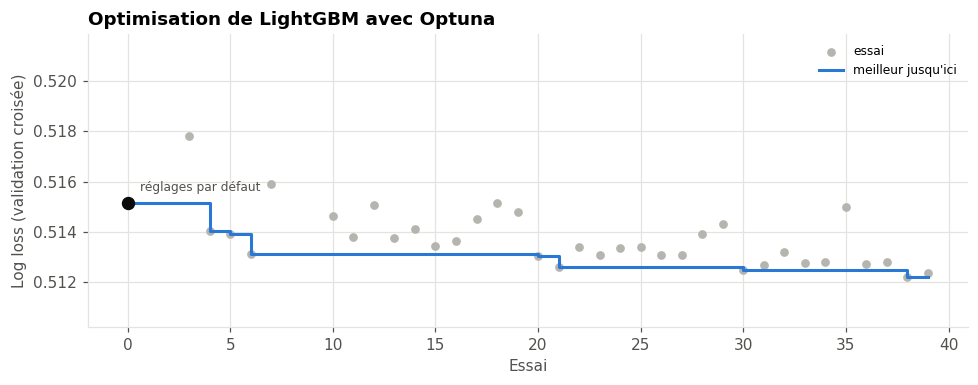

In [11]:
history = trials.sort_values("trial")
best_so_far = history["log_loss"].cummin()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(history["trial"], history["log_loss"], s=22, color="#b5b4ae", label="essai")
ax.plot(history["trial"], best_so_far, color=COLOR_CT, linewidth=2, drawstyle="steps-post",
        label="meilleur jusqu'ici")
ax.scatter([0], [default_ll], s=60, color=COLOR_TEXT, zorder=3)
ax.annotate("réglages par défaut", (0, default_ll), xytext=(8, 8), textcoords="offset points",
            fontsize=8, color=COLOR_TEXT_MUTED)
upper = history["log_loss"].quantile(0.9)
ax.set_ylim(best_so_far.min() - 0.002, max(upper, default_ll) + 0.003)
ax.set_xlabel("Essai")
ax.set_ylabel("Log loss (validation croisée)")
ax.set_title("Optimisation de LightGBM avec Optuna")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
save_fig(fig, "13_optuna_historique")
plt.show()

Les essais les moins bons sont hors du cadre, pour garder lisibles les écarts entre les meilleurs.

## 2. Comparaison des modèles

Tous les modèles utilisent les mêmes 49 variables et les mêmes plis de validation croisée.

| Modèle | Réglages |
| --- | --- |
| Régression logistique | variables standardisées |
| Random Forest | 300 arbres, `min_samples_leaf=20` |
| Réseau de neurones (MLP) | 2 couches cachées (64, 32), arrêt anticipé, variables standardisées |
| HistGradientBoosting | réglages par défaut de scikit-learn |
| LightGBM | réglages par défaut du projet |
| LightGBM optimisé | meilleurs hyperparamètres trouvés par Optuna |

In [12]:
candidates = {
    "Régression logistique": build_pipeline(LogisticRegression(max_iter=2000), scale=True),
    "Random Forest": build_pipeline(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED)),
    "Réseau de neurones (MLP)": build_pipeline(MLPClassifier(
        hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=SEED), scale=True),
    "HistGradientBoosting": build_pipeline(HistGradientBoostingClassifier(random_state=SEED)),
    "LightGBM": build_pipeline(make_lgbm(DEFAULT_PARAMS)),
    "LightGBM optimisé": build_pipeline(make_lgbm(best_params)),
}
cv = {}
for name, pipe in candidates.items():
    cv[name] = grouped_cv(pipe, train)
    print(f"{name} : terminé")

comparison = summarize_cv(cv).sort_values("log_loss").reset_index(drop=True)
comparison.to_csv(reports / "cv_modeles.csv", index=False)
comparison[["configuration", "accuracy", "accuracy_std", "roc_auc", "log_loss", "log_loss_std",
            "brier", "seconds"]].style.format(
    {"accuracy": "{:.2%}", "accuracy_std": "± {:.2%}", "roc_auc": "{:.4f}", "log_loss": "{:.4f}",
     "log_loss_std": "± {:.4f}", "brier": "{:.4f}", "seconds": "{:.0f} s"}).hide(axis="index")

Régression logistique : terminé
Random Forest : terminé
Réseau de neurones (MLP) : terminé
HistGradientBoosting : terminé
LightGBM : terminé
LightGBM optimisé : terminé


configuration,accuracy,accuracy_std,roc_auc,log_loss,log_loss_std,brier,seconds
LightGBM optimisé,71.13%,± 0.77%,0.8084,0.5122,± 0.0060,0.1755,27 s
LightGBM,70.89%,± 0.61%,0.8056,0.5152,± 0.0067,0.1770,11 s
Random Forest,70.65%,± 0.66%,0.8054,0.5154,± 0.0061,0.1767,56 s
HistGradientBoosting,70.92%,± 0.64%,0.8051,0.5159,± 0.0063,0.1771,12 s
Régression logistique,70.25%,± 0.51%,0.7960,0.5303,± 0.0068,0.1821,10 s
Réseau de neurones (MLP),68.35%,± 0.49%,0.7739,0.6032,± 0.0361,0.2024,216 s


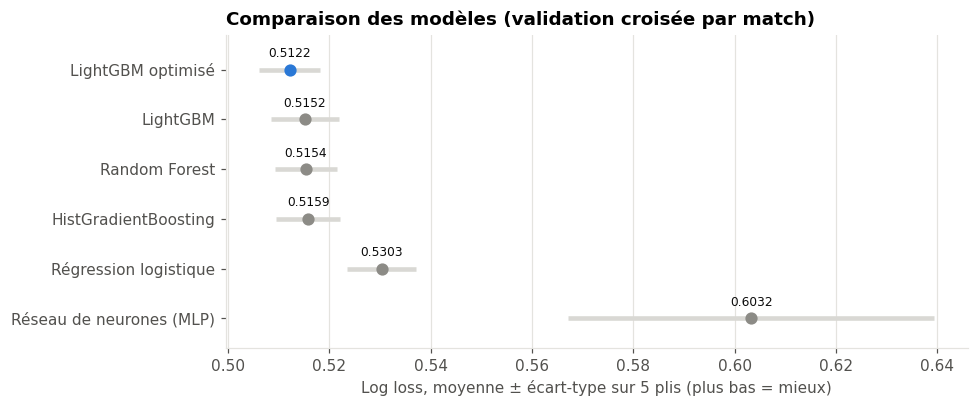

In [13]:
plot = comparison.sort_values("log_loss", ascending=False).reset_index(drop=True)
best_name = comparison.loc[0, "configuration"]

fig, ax = plt.subplots(figsize=(9, 3.8))
for y, row in plot.iterrows():
    color = COLOR_CT if row["configuration"] == best_name else "#8c8b86"
    ax.errorbar(row["log_loss"], y, xerr=row["log_loss_std"], fmt="o", color=color,
                ecolor="#d9d8d4", elinewidth=3, capsize=0, markersize=7)
    ax.text(row["log_loss"], y + 0.25, f"{row['log_loss']:.4f}", ha="center", fontsize=8,
            color=COLOR_TEXT)
ax.set_yticks(range(len(plot)), plot["configuration"])
ax.set_ylim(-0.6, len(plot) - 0.3)
ax.set_xlabel("Log loss, moyenne ± écart-type sur 5 plis (plus bas = mieux)")
ax.set_title("Comparaison des modèles (validation croisée par match)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "14_comparaison_modeles")
plt.show()

Les barres grises représentent l'écart-type entre les plis : quand deux intervalles se chevauchent largement, la différence entre les modèles n'est pas significative.

## 3. Modèle final

Le modèle retenu est entraîné sur tout le train, puis sauvegardé avec le pipeline complet (création des variables, encodage de la carte, modèle) dans `models/lightgbm_pipeline.joblib`. Il prend en entrée les colonnes brutes d'un snapshot et renvoie la probabilité de victoire des T. Le test n'a toujours pas été utilisé.

In [14]:
final_model = train_final_model(train, best_params)
path = save_model(final_model, best_params, len(train))
print(f"Modèle sauvegardé : {path.relative_to(ROOT_DIR)}")

example = train.sample(3, random_state=SEED)
cols = ["map", "time_left", "bomb_planted", "ct_players_alive", "t_players_alive", "ct_money", "t_money"]
example[cols].assign(proba_victoire_T=final_model.predict_proba(example)[:, 1].round(3))

Modèle sauvegardé : models\lightgbm_pipeline.joblib


,map,time_left,bomb_planted,ct_players_alive,t_players_alive,ct_money,t_money,proba_victoire_T
76800,de_nuke,94.95,False,5.0,5.0,2200.0,1650.0,0.265
91184,de_dust2,167.00,False,5.0,5.0,600.0,3250.0,0.450
90752,de_inferno,167.00,False,5.0,5.0,550.0,12900.0,0.737


## 4. Résumé des résultats

In [15]:
c = comparison.set_index("configuration")
print("=== Résumé ===")
print(f"Essais Optuna : {N_TRIALS}")
print(f"LightGBM log loss : défaut {default_ll:.4f} -> optimisé {study.best_value:.4f}")
print("Meilleurs hyperparamètres :")
for k, v in best_params.items():
    print(f"   {k:<18}: {v:.4g}" if isinstance(v, float) else f"   {k:<18}: {v}")
print("Comparaison (validation croisée) :")
for name, row in c.iterrows():
    print(f"   {name:<26}: accuracy {row['accuracy']:.2%} | AUC {row['roc_auc']:.4f} | "
          f"log loss {row['log_loss']:.4f} ± {row['log_loss_std']:.4f} | Brier {row['brier']:.4f} | {row['seconds']:.0f} s")

=== Résumé ===
Essais Optuna : 40
LightGBM log loss : défaut 0.5152 -> optimisé 0.5122
Meilleurs hyperparamètres :
   n_estimators      : 600
   learning_rate     : 0.01045
   num_leaves        : 36
   min_child_samples : 62
   subsample         : 0.8937
   colsample_bytree  : 0.5139
   reg_lambda        : 0.005572
Comparaison (validation croisée) :
   LightGBM optimisé         : accuracy 71.13% | AUC 0.8084 | log loss 0.5122 ± 0.0060 | Brier 0.1755 | 27 s
   LightGBM                  : accuracy 70.89% | AUC 0.8056 | log loss 0.5152 ± 0.0067 | Brier 0.1770 | 11 s
   Random Forest             : accuracy 70.65% | AUC 0.8054 | log loss 0.5154 ± 0.0061 | Brier 0.1767 | 56 s
   HistGradientBoosting      : accuracy 70.92% | AUC 0.8051 | log loss 0.5159 ± 0.0063 | Brier 0.1771 | 12 s
   Régression logistique     : accuracy 70.25% | AUC 0.7960 | log loss 0.5303 ± 0.0068 | Brier 0.1821 | 10 s
   Réseau de neurones (MLP)  : accuracy 68.35% | AUC 0.7739 | log loss 0.6032 ± 0.0361 | Brier 0.2024 |

## Conclusion

**Optimisation :** sur 40 essais, Optuna fait passer la log loss de LightGBM de 0,5152 (réglages par défaut) à 0,5122. Les meilleurs réglages combinent beaucoup d'arbres (600) avec un pas d'apprentissage faible (0,0105), des arbres de taille moyenne (36 feuilles) et un échantillonnage d'environ la moitié des variables par arbre (`colsample_bytree` = 0,51) : un compromis classique entre précision et régularisation.

**Comparaison des modèles :**

| Modèle | Accuracy | ROC-AUC | Log loss | Brier |
| --- | --- | --- | --- | --- |
| LightGBM optimisé | 71,13 % | 0,8084 | 0,5122 | 0,1755 |
| LightGBM | 70,89 % | 0,8056 | 0,5152 | 0,1770 |
| Random Forest | 70,65 % | 0,8054 | 0,5154 | 0,1767 |
| HistGradientBoosting | 70,92 % | 0,8051 | 0,5159 | 0,1771 |
| Régression logistique | 70,25 % | 0,7960 | 0,5303 | 0,1821 |
| Réseau de neurones (MLP) | 68,35 % | 0,7739 | 0,6032 | 0,2024 |

Les modèles à base d'arbres sont très proches : leurs écarts de log loss (environ 0,003) restent dans l'écart-type entre les plis (environ ± 0,006). Le LightGBM optimisé est néanmoins le meilleur sur les trois métriques de probabilité (ROC-AUC, log loss, Brier). Le réseau de neurones, l'approche de la première version du projet, est le moins bon et le plus instable (log loss 0,6032 ± 0,0361), pour un temps de calcul bien plus élevé : il n'est pas retenu.

**Modèle retenu :** LightGBM optimisé, entraîné sur tout le train et sauvegardé avec son pipeline complet dans `models/lightgbm_pipeline.joblib`. Par rapport à la meilleure règle simple (62,8 %), il apporte environ +8 points d'accuracy et des probabilités nettement mieux calibrées. Le test n'a pas encore été utilisé : il sert à l'évaluation finale de ce modèle.